In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))


outpath='./'
hyres_path = '../../IDP_REWEIGHTING/Ab42/rewM14DH_scaled/'
amber_path = '../../IDP_REWEIGHTING/Ab42/amber_M14DH_scaled/'
hyres_gpu_path = '../../IDP_REWEIGHTING/Ab42/hyres_gpu_M14DH_scaled/'
hyres_pf_path = '../../MD_DATA/Ab42/M14DH_scaled/'
amber_pf_path = '../../AMBER_IDPs/Ab42/M14DH_scaled/'
hyres_gpu_pf_path = '../../HYRES_GPU_IDPs/Ab42/M14DH_scaled/'
ensembles = ['a99SB*-ILDN TIP3P', 'HyRes-GPU', 'HyRes-Opt']
ensemble_paths = [amber_path, hyres_gpu_path, hyres_path]

In [2]:
# load experimental data

df = pd.read_csv(f'../../EXP_DATA/Ab42.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
print(np.min(F_exp))
print(np.max(F_exp))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

0.097352102653799
1.0


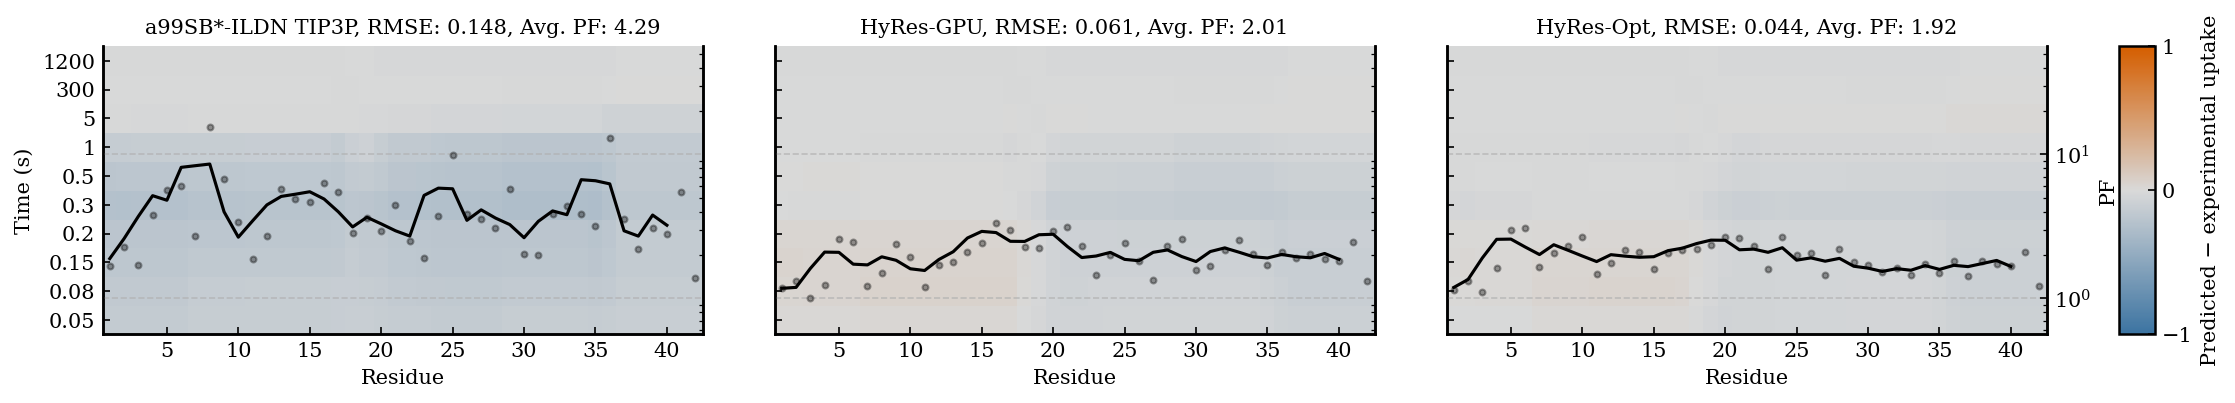

In [3]:

from matplotlib.colors import LinearSegmentedColormap

# comparison of HDX uptake differences + protection factors
protein = 'Ab42'
ensembles = ['a99SB*-ILDN TIP3P', 'HyRes-GPU', 'HyRes-Opt']
ensemble_paths = [amber_path, hyres_gpu_path, hyres_path]
pf_paths = [amber_pf_path, hyres_gpu_pf_path, hyres_pf_path]  # paths to O.npy and amideresidues.txt
exp_uptake = pd.read_csv(f'../../EXP_DATA/{protein}.csv')

# load predicted uptakes and statistics
all_pred_values, all_rmse, all_chi2 = [], [], []
for ensemble, path in zip(ensembles, ensemble_paths):
    if ensemble == 'HyRes-Opt': rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt")[0], np.loadtxt(path + "chi2r.txt")[0], np.load(path + "pred_uptakes.npy")[0]
    else: rmse, chi2r, pred_vals = np.loadtxt(path + "rmse.txt"), np.loadtxt(path + "chi2r.txt"), np.load(path + "pred_uptakes.npy")[0]
    all_pred_values.append(pred_vals); all_rmse.append(rmse); all_chi2.append(chi2r)

# load open/closed status and calculate PF = 1 / <f_open>
all_res, all_pf = [], []
for path in pf_paths:
    res, fopen = np.loadtxt(path + "amideresidues.txt").astype(int), np.load(path + "O.npy")
    PF = 1.0 / np.mean(fopen, axis=0)
    all_res.append(res); all_pf.append(PF)

# colour scale
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# residues and timepoints
times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_s = np.round(times, 2)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)
x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# build difference matrices
all_difference = []
for pred_vals in all_pred_values:
    df = exp_uptake.copy()
    df['Difference'] = pred_vals - df['Rel. Uptake']
    difference = np.full((len(times), len(residues)), np.nan)
    for i, t in enumerate(times):
        df_t = df[df['Time (s)'] == t]
        for j, resi in enumerate(residues):
            vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
            if len(vals) > 0: difference[i, j] = np.nanmean(vals)
    all_difference.append(difference)

# plot
fig, axes = plt.subplots(1, 3, figsize=(16, 3), sharex=True, sharey=True)
window_size = 3
kernel = np.ones(window_size) / window_size

for i, (ax, ensemble, difference, rmse, chi2, res, PF) in enumerate(zip(axes, ensembles, all_difference, all_rmse, all_chi2, all_res, all_pf)):
    im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)
    ax.set_title(f'{ensemble}, RMSE: {rmse:.3f}, Avg. PF: {np.mean(PF):.2f}', fontsize=10)
    ax.set_xlabel('Residue')
    ax.set_yticks(np.arange(len(times)) + 0.5)
    ax.set_yticklabels([f'{t:g}' for t in times_s])
    ax.tick_params(top=False, right=False)
    ax.spines['top'].set_visible(False)

    ax2 = ax.twinx()
    PF_smooth = np.convolve(PF, kernel, mode='valid')
    res_smooth = res[:len(PF_smooth)]
    ax2.scatter(res, PF, color='black', s=8, alpha=0.35, zorder=20)
    ax2.plot(res_smooth, PF_smooth, color='black', lw=1.5, zorder=21)
    ax2.set_yscale('log')
    ax2.set_ylim(10**-0.25, 10**1.75)
    ax2.tick_params(top=False)
    ax2.spines['top'].set_visible(False)

    if i == len(axes) - 1: ax2.set_ylabel('PF')
    else: ax2.set_yticklabels([]); ax2.tick_params(right=False)

axes[0].set_ylabel('Time (s)')

plt.subplots_adjust(left=0.08, right=0.89, bottom=0.18, top=0.82, wspace=0.12)
cax = fig.add_axes([0.92, 0.18, 0.015, 0.64])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_ensemble_uptake_difference_heatmaps_PF_M14DH_scaled.pdf', dpi=300, bbox_inches='tight')
plt.show()